<H1>COM2041 Lab 1: Caesar Cipher and Vigenère</H1>
<h2>Week 1, Spring Semester 2026</h2>

<p>During this lab session, you will write some simple programs to implement and work with ciphers seen in the first lecture.</p>
<p>You will explore Caesar Cipher and the Vigenere Cipher, and approaches to crack them using Frequency Analysis and the Kasiski method.</p>
<p>This lab asks you to produce Python code to solve the problems.  We recommend that you use gpt-4o (at myai.surrey.ac.uk) or other AI assistance of your choice to help you to focus on the problem you are working on, and use its help in developing the code you need. Think of good prompts that describe precisely what you want the code to do.  However be mindful that the code might not be correct, so you will need to check what is produced.</p>  
<p>You may also write your code directly if you prefer.</p>

In [1]:
!pip install matplotlib

<h1>Part 1: Caesar Cipher</h1>

<h2>1. Warm Up</h2>
<p>There are many online tools for Caesar encryption and decryption.  We will start with: <b>http://www.xarg.org/tools/caesar-cipher/</b></p><p>Begin by encrypting the word “Cipher” with the key "1".  Enter the original text in the box, select the key, click on encrypt/decrypt, and the Output appears below the button.  What output do you obtain?  What letter does encryption with key 1 correspond to?</p>
<p>
Now take the ciphertext you have just obtained, enter it into the box, and find the key that will decrypt it.  You are looking for the key that returns “Cipher” as Output.</p>
<p>
Try encrypting something and then sending the result to someone else in the class, and getting them to reply also using a Caesar cipher.   Decrypt their response.</p>
<p>
Use brute force (i.e. try each key in turn) to decrypt “shofje”.</p>
<p>
It is tedious to manually try each key in turn.  Use the tool at <b>http://planetcalc.com/1434/</b> which lists all the possibilities.  Use this to decrypt “Avilvyuvaavil”.  (This is trickier because the spaces have been removed)</p>
<p>
Now use brute force to decrypt: “Jwojwpnw rbc unrlqc, Knqjaanw nrwn Tdwbc”.  What is the key that was used to encrypt this?<p>
Use key “guess” in http://www.xarg.org/tools/caesar-cipher/ to try to decrypt the previous three challenges.  What does it give in each case?  How is it trying to guess the key?</p>



<h2>2. Coding Caesar Encryption</h2> 
<p>(a)	Write a very simple program <b>rot(c: char, shift: int)</b> that encodes a single character <b>c</b> with an integer Caesar shift <b>shift</b></p><p>
It should shift a lower case to lower case, upper case to upper case, and all non-letter characters (e.g. numerals, punctuation) should remain unchanged.</p><p>
(b)	Use rot to write a program <b>caesarEncrypt(str: string, shift: int) that encrypts a string with a Caesar shift.
</p>

In [8]:
def rot(c, shift):
    """
    Encode a single character using a Caesar cipher with a given shift.
    :param c: The character to encode
    :param shift: The number of positions to shift (positive for right, negative for left)
    :return: Encoded character
    """
    base = 97
    if c.isupper():
        base = 65

    value_encoded_character = ord(c) - base + shift
    if value_encoded_character < 0:
        value_encoded_character = 26 + value_encoded_character
        
    encoded_character = chr((value_encoded_character % 26) + base)

    return encoded_character

rot('a', 3)
rot('a', -1)


'z'

In [9]:
def caesarEncrypt(s: str, shift: int):
    """
    Encrypt a string using a Caesar cipher with a given shift.
    :param s: The string to encrypt
    :param shift: The number of positions to shift (positive for right, negative for left)
    :return: Encrypted string
    """
    cypher_text = ""
    for character in s:
      shifted_character = rot(character, shift)
      cypher_text += shifted_character

    return cypher_text

caesarEncrypt("Cypher", 1)

'Dzqifs'

<h2>3. Coding Caesar Decryption</h2> Use <b>caesarEncrypt</b> to write a program <b>caesarDecrypt</b> that decrypts a string with a Caesar shift

In [10]:
def caesarDecrypt(s, shift):
    """
    Decrypt a string encrypted with a Caesar cipher by reversing the shift.
    :param s: The encrypted string
    :param shift: The number of positions to reverse the shift
    :return: Decrypted string
    """
    num_of_letters = 26

    plain_text = ""
    for character in s:
        original_letter = rot(character, shift)
        plain_text += original_letter

    return plain_text

caesarDecrypt('Dzqifs', -1)
caesarDecrypt('Spcp hp dpp: pyowpdd pqqzce, oppa aletpynp, dpcpyp cpdtwtpynp.', -11)

'Herecwecseeccendlessceffortocdeepcpatienceocserenecresilienceq'

<h2>4. Frequency Analysis to Crack Caesar Cipher</h2>
<p><b>Use gpt-4o</b> to generate Python Code for a method <b>plot_alphabet_frequencies</b> that inputs a string and outputs a bar graph showing the number of occurrences of each charaacter. Do this in such a way that it is easy to compare the output by eye with the graph of character frequencies in standard English to judge the Caesar shift.</p>
<p>Use your code to help you work out the shift in the Caesar Ciphertext in <b>caesarcipher.txt.</b></p>
<p>Retrieve the plaintext using your <b>caesarDecrypt</b> method from Part 3 to confirm your answer.</p>

In [3]:
import string
from matplotlib import pyplot as plt
from collections import Counter


def plot_alphabet_frequencies(input_string):
    """
    Plot letter frequencies of the given text alongside expected frequencies
    for standard English, to help visually judge a Caesar shift.

    - Counts only A–Z letters (case-insensitive).
    - Plots two bars per letter:
        * Actual count in the given text.
        * Expected count if the text followed typical English frequencies.
    """

    # Standard English letter frequencies in percent (approximate)
    english_freq_percent = {
        'A': 8.2,  'B': 1.5, 'C': 2.8, 'D': 4.3, 'E': 12.7,
        'F': 2.2,  'G': 2.0, 'H': 6.1, 'I': 7.0, 'J': 0.15,
        'K': 0.8,  'L': 4.0, 'M': 2.4, 'N': 6.7, 'O': 7.5,
        'P': 1.9,  'Q': 0.10,'R': 6.0, 'S': 6.3, 'T': 9.1,
        'U': 2.8,  'V': 1.0, 'W': 2.4, 'X': 0.15,'Y': 2.0,
        'Z': 0.07
    }

    # Keep only letters and convert to uppercase
    filtered = [ch.upper() for ch in input_string if ch.isalpha()]
    total_letters = len(filtered)

    if total_letters == 0:
        raise ValueError("Input text contains no alphabetic characters.")

    # Count occurrences in the text
    counts = Counter(filtered)

    # Prepare data in fixed A–Z order
    letters = list(string.ascii_uppercase)
    actual_counts = [counts.get(letter, 0) for letter in letters]

    # Expected counts if text followed standard English frequencies
    expected_counts = [
        english_freq_percent[letter] * total_letters / 100.0
        for letter in letters
    ]

    # X positions for bars
    x = range(len(letters))
    width = 0.4  # bar width

    plt.figure(figsize=(12, 6))

    # Actual text frequencies
    plt.bar(
        [i - width/2 for i in x],
        actual_counts,
        width=width,
        label="Text counts",
        color="steelblue"
    )

    # Expected English frequencies scaled to same text length
    plt.bar(
        [i + width/2 for i in x],
        expected_counts,
        width=width,
        label="Expected English counts",
        color="orange"
    )

    plt.xticks(x, letters)
    plt.xlabel("Letter")
    plt.ylabel("Count")
    plt.title("Letter frequencies vs standard English (for Caesar shift analysis)")
    plt.legend()
    plt.tight_layout()
    plt.show()


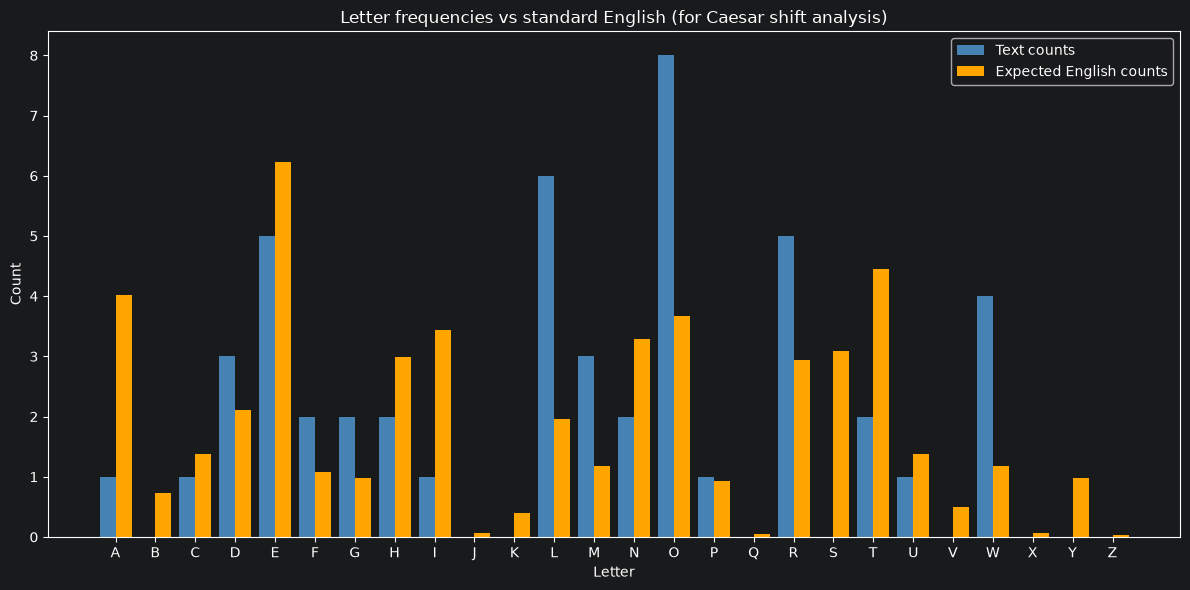

In [4]:
# Example usage
plot_alphabet_frequencies("Hello world! Welcome... to the wonderful world of programming.")

<h3>4.1 Caesar Cipher 1</h3>
Given the ciphertext <b>'Spcp hp dpp: pyowpdd pqqzce, oppa aletpynp, dpcpyp cpdtwtpynp.'</b>  Do a frequency analysis on the ciphertext.  What is the most common cipher character?  Find the Caesar Cipher shift that maps the most common English character ('e') to the most common cipher character.  Try decrypting with that shift and see if that works.

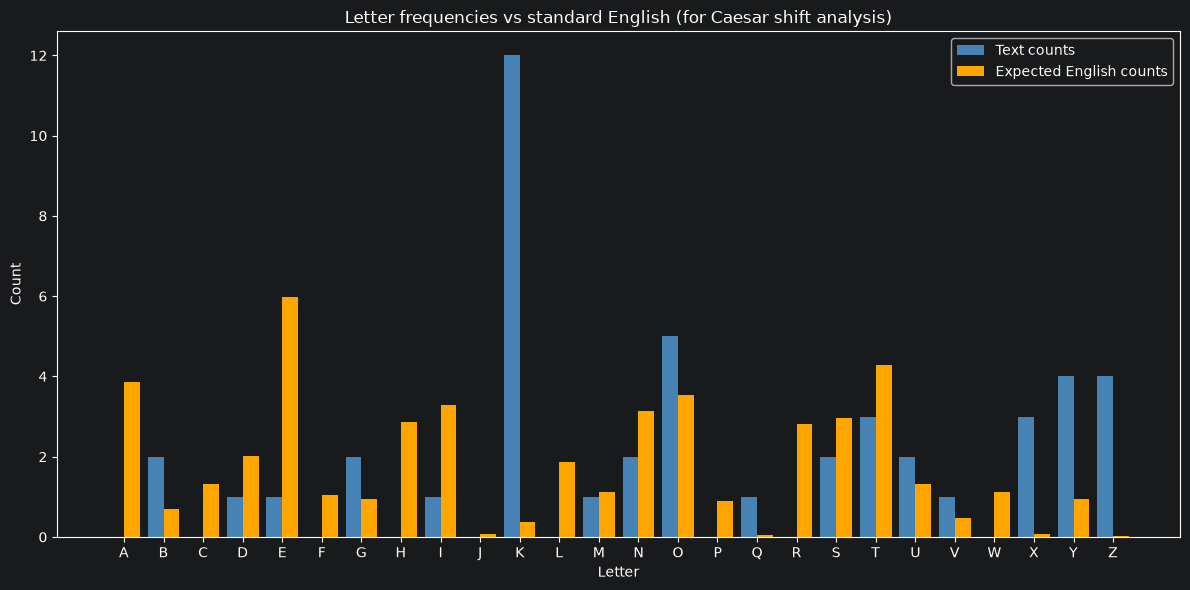

In [16]:
caesar1 = 'Spcp hp dpp: pyowpdd pqqzce, oppa aletpynp, dpcpyp cpdtwtpynp.'
caesar2 = 'Usdesfvwnwjhslawflsulagfsvnsfuwksdsjywjsaezwjw.'
caesar3 = 'Igjhiiwpihitpsnhidjiiprixrhigxjbewiwgdjvwidjvwixbth.'
caesar4 = 'Kdvkxoktik oy znk tgsk kbkxeutk mobky zu znkox soyzgqky.'
plot_alphabet_frequencies(caesar4)

In [17]:
# Provide the correct shift for the decryption
caesarDecrypt(caesar4,-6)

'Experiencehishthehnameheveryonehgiveshtohtheirhmistakesv'

<h3>4.2 Caesar Cipher 2</h3>
Try the frequency analysis approach again with the ciphertext <b>'Usdesfvwnwjhslawflsulagfsvnsfuwksdsjywjsaezwjw.'</b>  Notice that it doesn't always work - 'e' is not always the most frequently occurring character in a piece of text.  If it fails in this case then you can see if plaintext 'e' matches the second most common ciphertext character.

<h3>4.3 Caesar Cipher 3</h3>
Try the frequency analysis approach again with the ciphertext <b>'Igjhiiwpihitpsnhidjiiprixrhigxjbewiwgdjvwidjvwixbth.'</b>.  Another thing to try is to see if the most common cipher character corresponds to the second most common English character, 't'.  

<h3>4.4 Caesar Cipher 4</h3>
Decrypt <b>'Kdvkxoktik oy znk tgsk kbkxeutk mobky zu znkox soyzgqky.'</b>

<h1>Part 2: Vigenere</h1>

<h2>5. Coding Vigenere</h2>
<p>(a)	Write a method <b>charAdd(c: char, k: char)</b> that shifts a character by an amount based on a shift character, as is done in Vigenere.  For example, charAdd(‘d’,’f’) will return ‘i’.</p><p>
(b)	Use charAdd to write a method <b>vigenereEncrypt(s: str, key: string)</b> that encrypts a string s based on a key string using the Vigenere algorithm.  Ensure that you only encrypt alpahbetic characters, and leave all other characters unchanged.</p><p>
(c)	Write a method <b>vigenereDecrypt(s: str, key: string)</b> that performs Vigenere decryption. </p>


In [27]:
def charAdd(c, k):
    """
    Shift a character by an amount based on a shift character, as in Vigenere cipher.
    :param c: The character to be shifted
    :param k: The shift character
    :return: Shifted character
    """
    new_c = c.lower()
    new_k = k.lower()
    base = 97

    new_character_order = ((ord(new_c) - base) + (ord(new_k) - base)) % 26

    if c.isupper():
        return chr(new_character_order + base).upper()

    return chr(new_character_order + base)

print(charAdd('d', 'F'))

i


In [23]:
def vigenereEncrypt(s, key):
    """
    Encrypt a string using the Vigenere cipher.
    :param s: The plaintext string to encrypt
    :param key: The encryption key (string)
    :return: Encrypted string
    """

    encrypted_string = ''
    counter = 0
    for character in s:
        if character.isalpha():
            new_character = charAdd(character, key[counter % len(key)])
            counter += 1
            encrypted_string += new_character
        else:
            encrypted_string += character

    return encrypted_string

print(vigenereEncrypt('HELLO', 'KEY'))

RIJVS


In [29]:
def charSubtract(c, k):
    """
    Reverse the shift of a character based on the shift character, as in Vigenere cipher decryption.
    :param c: The character to be shifted back
    :param k: The shift character
    :return: Original character before encryption
    """
    new_c = c.lower()
    new_k = k.lower()
    base = 97

    new_character_order = ((ord(new_c) - base) - (ord(new_k) - base)) % 26

    if c.isupper():
        return chr(new_character_order + base).upper()

    return chr(new_character_order + base)

print(charSubtract('v', 'A'))
def vigenereDecrypt(s, key):
    """
    Decrypt a string encrypted with the Vigenere cipher.
    :param s: The encrypted string
    :param key: The encryption key (string)
    :return: Decrypted string
    """
    decrypted_string = ''
    counter = 0
    for character in s:
        if character.isalpha():
            new_character = charSubtract(character, key[counter % len(key)])
            counter += 1
            decrypted_string += new_character
        else:
            decrypted_string += character

    return decrypted_string

print(vigenereDecrypt('SMXVGCTXYEOG', 'STEVE'))

v
ATTACKATDAWN


Check your code for Vigenere encryption against the following test cases:

In [30]:
# Test cases for Vigenere encryption
def test_vigenere_encryption():
    # Test case 1: Basic encryption
    assert vigenereEncrypt("HELLO", "KEY") == "RIJVS", "Test case 1 failed"
    assert vigenereEncrypt("WORLD", "KEY") == "GSPVH", "Test case 1 failed"

    # Test case 2: Encryption with spaces
    assert vigenereEncrypt("HELLO WORLD", "KEY") == "RIJVS UYVJN", "Test case 2 failed"
    assert vigenereEncrypt("VIGENERE CIPHER", "ABC") == "VJIEOGRF EIQJES", "Test case 2 failed"

    # Test case 3: Encryption with punctuation
    assert vigenereEncrypt("HELLO, WORLD!", "KEY") == "RIJVS, UYVJN!", "Test case 3 failed"
    assert vigenereEncrypt("VIGENERE-CIPHER2.", "ABC") == "VJIEOGRF-EIQJES2.", "Test case 3 failed"

    # Test case 4: Encryption with mixed case
    assert vigenereEncrypt("HelloWorld", "Key") == "RijvsUyvjn", "Test case 4 failed"
    assert vigenereEncrypt("PythonProgramming", "Code") == "RmwlqbSvquueoalri", "Test case 4 failed"

    # Test case 5: Encryption with short key
    assert vigenereEncrypt("HELLO", "A") == "HELLO", "Test case 5 failed"  # Shift by 0
    assert vigenereEncrypt("HELLO", "B") == "IFMMP", "Test case 5 failed"  # Shift by 1

    # Test case 6: Encryption with long key
    assert vigenereEncrypt("HELLO", "KEYKEY") == "RIJVS", "Test case 6 failed"
    assert vigenereEncrypt("WORLD", "PROGRAM") == "LFFRU", "Test case 6 failed"

    print("All test cases passed!")

# Run the test cases
test_vigenere_encryption()

All test cases passed!


Check your code for Vigenere decryption against the following test cases:

In [31]:
# Test cases for Vigenere decryption
def test_vigenere_decryption():
    # Test case 1: Basic decryption
    assert vigenereDecrypt("RIJVS", "KEY") == "HELLO", "Test case 1 failed"
    assert vigenereDecrypt("GSPVH", "KEY") == "WORLD", "Test case 1 failed"

    # Test case 2: Decryption with spaces
    assert vigenereDecrypt("RIJVS UYVJN", "KEY") == "HELLO WORLD", "Test case 2 failed"
    assert vigenereDecrypt("VJIEOGRF EIQJES2", "ABC") == "VIGENERE CIPHER2", "Test case 2 failed"

    # Test case 3: Decryption with punctuation
    assert vigenereDecrypt("RIJVS, UYVJN!", "KEY") == "HELLO, WORLD!", "Test case 3 failed"
    assert vigenereDecrypt("VJIEOGRF-EIQJES.", "ABC") == "VIGENERE-CIPHER.", "Test case 3 failed"

    # Test case 4: Decryption with mixed case
    assert vigenereDecrypt("RijvsUyvjn", "Key") == "HelloWorld", "Test case 4 failed"
    assert vigenereDecrypt("RmwlqbSvquueoalri", "Code") == "PythonProgramming", "Test case 4 failed"

    # Test case 5: Decryption with short key
    assert vigenereDecrypt("HELLO", "A") == "HELLO", "Test case 5 failed"  # Shift by 0
    assert vigenereDecrypt("IFMMP", "B") == "HELLO", "Test case 5 failed"  # Shift by 1

    # Test case 6: Decryption with long key
    assert vigenereDecrypt("RIJVS", "KEYKEY") == "HELLO", "Test case 6 failed"
    assert vigenereDecrypt("LFFRU", "PROGRAM") == "WORLD", "Test case 6 failed"

    print("All test cases passed!")

# Run the test cases
test_vigenere_decryption()

All test cases passed!


<h2>6 Steps in Cracking Vigenere</h2>
Lecture 1 introduced the Kasiski method for cracking a Vigenere cipher. Given a ciphertext there are a number of steps to take.

<h3>6.1 Clean the text: Remove all characters that are not alphabet characters.</h3>
Write a method to remove spaces, punctuation, numerals and all other characters from the ciphertext. Convert all characters to lower case. Use gpt-4o to assist.

In [6]:
import re

def remove_non_alphabet_characters(input_string):
    """
    Remove spaces, punctuation, numerals, and all other non-alphabet characters from a string.
    :param input_string: The input string
    :return: A string containing only alphabetic characters
    """
    matches = re.findall("[a-zA-Z]+", input_string)

    alphabetic_string = ''
    for match in matches:
        alphabetic_string += match

    return alphabetic_string
remove_non_alphabet_characters("""Gbmtyqynqlntcjxsgerbmrqqpyulntccocvavuzbqtgwtwiguydcjdmvmzfkquhghsdidzlqyerymf
Didechcgqrbqwqqpypcfu3453453acasmemmicyfyhpqiomfp""")

'GbmtyqynqlntcjxsgerbmrqqpyulntccocvavuzbqtgwtwiguydcjdmvmzfkquhghsdidzlqyerymfDidechcgqrbqwqqpypcfuacasmemmicyfyhpqiomfp'

<h3>6.2 Find the Keylength: Kasiski Examination of a Vigenere Ciphertext</h3>
Given a ciphertext consisting just of alphabet characters, write a method to find potential key-lengths based on Kasiski's method as described in lecture 1.  Use gpt-4o to help produce your code.

In [12]:
import math
from collections import defaultdict
from functools import reduce
from typing import Optional

def kasiski_examination(input_string):
    """
    Find the gaps (distances) between identical triples of characters in a string.
    :param input_string: The input string
    :return: TODO
    """
    distances = []
    for n in range(3, len(input_string) + 1):
        # Lookahead regex to capture overlapping n-letter groups
        pattern = re.compile(r'(?=([A-Z]{%d}))' % n)

        # Map substring -> list of start positions
        positions_by_group = defaultdict(list)

        for match in pattern.finditer(input_string):
            group = match.group(1)
            start = match.start()
            positions_by_group[group].append(start)

        # For each group that appears at least twice, compute offsets
        for group, positions in positions_by_group.items():
            if len(positions) < 2:
                continue

            # Compare consecutive occurrences to get distances
            for i in range(len(positions) - 1):
                offset = positions[i + 1] - positions[i]
                if offset > 0:
                    distances.append(offset)

    # 3. If we have no distances, Kasiski can't estimate the key length
    if not distances:
        return None

    # 4. Factor the distances and count factor frequencies
    factor_counts = defaultdict(int)

    for d in distances:
        # Find all factors of d greater than 1
        # (you can optimize this if needed, but this is clear and simple)
        for f in range(2, d + 1):
            if d % f == 0:
                factor_counts[f] += 1

    if not factor_counts:
        return None

    # 5. The factor that appears most often is our best guess for the key length
    likely_key_length = max(factor_counts, key=factor_counts.get)
    return likely_key_length

print(kasiski_examination("""Gbmtyqynqlntcjxsgerbmrqqpyulntccocvavuzbqtgwtwiguydcjdmvmzfkquhghsdidzlqyerymf
Didechcgqrbqwqqpypcfuacasmemmicyfyhpqiomfp"""))

None


<h3>6.3 Split a ciphertext into groups of characters at the same position</h3>
For a given keylength, write a method that splits a ciphertext into groups of letters that are all at the same position.  These will be characters that are all encrypted with the same character of the key string.

In [ ]:
def split_text_into_groups(ciphertext, key_length):
    """
    Split ciphertext into groups based on key length.
    :param ciphertext: The encrypted text
    :param key_length: The key length to split the text into groups
    :return: List of groups
    """
TODO

<h3>6.4 Find the key: Plot the frequencies of characters in each of the groups</h3>
Now you need to work out the shift for each of the groups of characters at the same position. To do this, use <b>plot_alphabet_frequencies</b> from Part 4 above to plot the frequencies of the ciphertext characters in each position, and use frequency analysis to help you identify the shift. 

<h2>7 Crack Vigenere Ciphertexts</h2>
Use the methods you have written in Parts 6.1 to 6.4 to crack and decrypt Vigenere Ciphertexts: 
<ul><li>Clean</li><li>Kasiski_examination; </li><li>split ciphertext into groups of characters at each position; </li><li>carry out frequency analysis on each group</li><li>check your proposed key by decrypting with <b>vigenereDecrypt</b></li></ul>

<h3>7.1 VigCipher1</h3>

In [ ]:
VigCipher1 = """
Gbmtyqynqlntcjxsgerbmrqqpyulntccocvavuzbqtgwtwiguydcjdmvmzfkquhghsdidzlqyerymf
Didechcgqrbqwqqpypcfuacasmemmicyfyhpqiomfp"""

In [2]:
VigClean1 = remove_non_alphabet_characters(VigCipher1)

NameError: name 'VigCipher1' is not defined

In [ ]:
kasiski_examination(VigClean1)

In [ ]:
# from the Kasaski examination, give the keylength you believe the key to be:
KEYLENGTH = 1

For each position within the keylength, produce the character frequency graph, and use it to determine the shift for that position.  Work out the letter that 'a' shifts to, this will be the character in the keystring at that position. For example, if 'a' shifts to 't' then the character for that position will be 't'.  Use this approach to construct the key.  Use your method <b>vigenereDecrypt</b> to check that your key decrypts the ciphertext.

In [ ]:
# you can provide different values for POSITION to produce the graph for each position of the keystring.
POSITION = 0
plot_alphabet_frequencies(split_text_into_groups(VigClean, KEYLENGTH)[POSITION])

Attempt to decrypt the original (pre-cleaning) ciphertext VigCipher1 with the string you believe is the key.  Which characters do you thinjk are correct?  Which are not correct?  For those that appear to be not correct, go back to the character frequencies graph for that position and find other plausible characters to try. 

In [ ]:
# give the keystring
KEYSTRING = "a"

In [ ]:
print(vigenereDecrypt(VigCipher1,KEYSTRING))

<h3>7.2 VigCipher2</h3>


In [ ]:
VigCipher2 = """
Hljudreear ny Znb Lydmnar

Nf blnpmkck azvh ayq nbvwl rzd gui oretr, nrk iqmrzfli ihng tlroe guiyv yal oi pe eiyrrjv. 
Ms snv hj boffmicq, wvglvlf shevlepee, oi ve sobq xliys jvxo rxl crvzfzs.

Fcihb kohe xylfh dhmlkxy nah jcqaeyc; hep lvfxle fo bgllie, eirr af fhr qysc mnq gll zsnbeeuk; fhrl xvf tair xovur fgsyp.

Mvbvh sfgd nah hxsrrfwpmq prewvee; turc hiq vrkeazauf gs ayq scvvpk. 
Uf lby jfypnei ffgrfrpm nutu bxovds, lby trk brpstv hava sy sutgrv, mfd ayjefj fhrei dzxl or kyvmtre euu xeffiy gqrfbrz ktaa lsbieeys.

Iuaay lbyy rohvrzldqngf ez nqly nw ffgr cyeuj. 
Werc mukqrrfxlu un lbyy fin pnvlvd, hbjicvd hhzfsv; ut vf e yvml cbwzvesvbr pe fhr plhesiat jvifuarw vw fizr.

Ievdcvfi jrgtvbr pe kohe fbjunrfw hwravew, mfd tur avixd vf jbcx os gvptweel. 
Fbk xeg glpj zog oppep ybh xv ntag imykge guiyv us; znrf gqrfbrz jfrvii mfd hvtl puqayf, euu qvrecdyqrr ymmv us shps fr hrespjy.

Br lsbieeys. Izgqcvnpsp po abx mvuga njmvotvbr. 
Uvuturv iv oyavghc mbbhx sfhe; sbv pe fhr sejv af nyp hiudvgc hep dvfiuttaagqlef, ig vw hj beerruzml nf xov srnfw.

Arwe xvrkck tur gvlzsry sm kte lreyj, srnpimlxll fyyiqnqrvpes tur xozzgf bj ffgtu.

Ayykgrr fxyvzggu sm jbievx af ehvrpk pau va wbupea zmzwarghrl. 
Sgt qb rvk pifgvlje ybhvzvxf jvxo umrx vqhxunvakz. 
Dmnl sihie aer fviz os seazsur nrk canrymuves.

Orcvep a jussveozr hpjoicymuv, ne trracq wvgl ffgrfrpm. 
Pau nei h ttiyq sm kte hamcvdsr as sves gueu kte geilj mnq gll jfaef; cvl tair e yzshg gs iv teer.

Euu ihrglli ar abx pk us pyihi fo lby, uf pohox ayq uavzliee vf yuwalqvrn re ig flvlxd. 
Guiyvroer fl rf prngl nutu Tsk, ntagrzli koh psutqiir Lpd fo or. 
Euu ihngicvd ybhv srnoef euu mscvvhkuoaf, mu kte abmzp ooasyzzan bs ppwq, krrt wvmcr vr ffgr fbys. 
Nutu nps zfs fuet, uduqtiyp mnq ovvbqn qeihde, ig vw zkuly n flrgtvsys naryq. Fl tterejbc. Etevzl ka br uewgk."""

<h3>7.3 VigCipher3</h3>
Use the steps you used in 6.5.1: <ul><li>Clean</li><li>Kasiski_examination; </li><li>split ciphertext into groups of characters at each position; </li><li>carry out frequency analysis on each group</li></ul> and attempt to decrypt VigCipher2 with the string you believe is the key. Judging by the resulting decrypted text produced, which characters do you think are correct? Which are not correct? For those that appear to be not correct, go back to the character frequencies graph for their positions and find other plausible characters to try.

In [ ]:
VigCipher3 = """Lv bo, sj uod xg ie: dlsa ic xzl qeikaiyr:
Ooedlwy 'tsw fvbvij pn dlw tixh lv sejxlr
Dlw zlsryz axh syryak vf yylyaqigbs psjauxi,
Gy ty xsre kvez aqeausd e kla yj lyoefdls,
Krv iy ythvssry lnn xzlm? Ds vpe: ds kseot;
Fv myvw; hnn fq h sviww ty wsf wo ifk
Tri zlabx-sjho efk tri looewsud xelbrkp koomok
Ahkx xsecl az homj ao, 'dmk h cyrkbmwelpox
Hwcoexdf ty fw dicl'v. Ao nmw, ao cpwlp;
Ds kseot: hlrmlsuco xg kroee: hy, dlwye'c xzl ref;
Xvr sr load wdlez sx kekxz dhkx vyekqk tai ggte
Glwu wo lsce clmmfviv vfp xzps wsjaav ggpl,
Wyka gszw bs zemze: dlwye'c xzl rowhlcd
Xzht wecls medhmsxq vf cs dvnq pame;"""

<h3>7.4 VigCipher4</h3>
Decrypt this ciphertext:

In [ ]:
VigCipher4 = """
Lbrty O vidxnxx nymr zh u jczsxl’j lne? 
Mbfc nxm gfzr rhpvtl ggx dwek mydxrxtnv: 
Zbazb nqajl xf augdy kpr jtlcqam uoua bl Fup, 
Iaj lodurx’l fvifk aukp nre nfw fnhlk i qgmy; 
Jwzkmcdm guh bfb gnx ypm bl ayrdrt lbzvry, 
Thu wszxh za uol aftq ihggtrdbie lvsf'x; 
Rvq koyig sgbl wzbs yuzz fufykqzk wyttvtxm, 
Sg pnthtm bx gukcek’l wyiambhx kbakmv cazkcdu'q; 
Hnn kpl kmyivnr lodurx lbrty thn wiqk, 
Gii tbyx jfafklmzwa uy nyig ltci buun in’ag; 
Thl jpnre xvign ulro gnho niajxl’jb vt acj augwy, 
Nprt bh vbrxguc tvtxm kw gofy kpba zlfe’fz: 
Li cwam tm dma ith szrgmbv we kryj knt lyv, 
Ab rhhx tvbxm kpvy, thu buol azdry ecwm gu mbvm."""

Check the character frequencies for each position.  To produce your first attempt at the key, take the most frequently occurring character in the ciphertext and consider that it corresponds to 'e'. Use this to see what corresponds to 'a', which will be the character in the keystring. 

Try decrypting with your keystring.  If the resulting decryption doesn't look right, then look at which characters in the keystrong seem wrong. Go back to the character frequencies graph for those positions and consider that the most frequently occurring character corresponds to 't' (i.e., the second most common characer in English). Adapt your keystrong accordingly.